In [ ]:
!pip install tensorflow

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray
from typing import Sequence, List, Tuple
from tensorflow.keras.datasets import mnist
from scipy.special import softmax
from collections.abc import Sequence
np.random.seed(42)

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

print(X_train.shape)
print(y_train.shape)

(60000, 784)
(60000,)


We use Xavier–Glorot weight initialization, defined by
$$
    W^{(i)} = \sqrt{\frac{6}{n^{(i+1)}+n^{(i)}}}
    \begin{bmatrix}
    Z_1 & \cdots & Z_{n^{(i)}}
    \end{bmatrix},
$$
where $Z_1,\ldots,Z_{n^{(i)}}$ are independent, identically distributed random vectors, each uniformly distributed on $[-1,1]^{n^{(i+1)}}$.

Whereas biases are initially set to $0$s.

In [ ]:
class MultiLayerPerceptron:

    def __init__(
        self,
        sizes: List[int] | None = None,
    ) -> None:
        self.sizes: List[int] = [784, 30, 10] if sizes is None else sizes
        self.weights: List[NDArray[np.float64]] = [
            (6/(self.sizes[i + 1] + self.sizes[i]))**0.5 *
            (1 - 2 * np.random.rand(self.sizes[i + 1], self.sizes[i]))
            for i in range(len(self.sizes) - 1)
        ]
        self.biases: List[NDArray[np.float64]] = [
            np.zeros(self.sizes[i + 1])
            for i in range(len(self.sizes) - 1)
        ]
        self.memo_w: List[NDArray[np.float64]] = [
            np.zeros_like(w) for w in self.weights
        ]
        self.memo_b: List[NDArray[np.float64]] = [
            np.zeros_like(b) for b in self.biases
        ]


    def predict(
        self,
        x_mini_batch: NDArray[np.float64],
    ) -> NDArray[np.intp]:
        z = x_mini_batch

        for i in range(len(self.sizes) - 1):
            a = z @ self.weights[i].T + self.biases[i]
            z = np.tanh(a) if i < len(self.sizes) - 2 else softmax(a, axis=1)

        return np.argmax(z, axis=1)


    def forward(
        self,
        x_mini_batch: NDArray[np.float64],
        y_mini_batch: NDArray[np.uint8],
    ) -> Tuple[List[NDArray[np.float64]], float]:
        z = x_mini_batch
        activations = [z]

        for i in range(len(self.sizes) - 1):
            a = z @ self.weights[i].T + self.biases[i]
            z = np.tanh(a) if i < len(self.sizes) - 2 else softmax(a, axis=1)
            activations.append(z)

        probs = z[np.arange(len(y_mini_batch)), y_mini_batch]
        loss = np.mean(-np.log(probs + 1e-12))

        return activations, loss


    def backward(
        self,
        x_mini_batch: NDArray[np.float64],
        y_mini_batch: NDArray[np.uint8],
        activations: List[NDArray[np.float64]],
    ) -> Tuple[NDArray[np.float64]]:

        grads_w = [None] * (len(self.sizes) - 1)
        grads_b = [None] * (len(self.sizes) - 1)
        z = activations[len(self.sizes) - 1]
        delta = z.copy()
        delta[np.arange(len(y_mini_batch)), y_mini_batch] -= 1

        for i in range(len(self.sizes) - 2, -1, -1):
            grads_w[i] = delta.T @ activations[i]
            grads_b[i] = np.sum(delta, axis=0)

            if i > 0:
                delta = (
                    (delta @ self.weights[i]) *
                    (1 - activations[i] * activations[i])
                )

        return grads_w, grads_b


    def evaluate(self,
                 x_test: NDArray[np.float64],
                 y_test: NDArray[np.uint8],
                 batch_size: int,
    ) -> float:
        N = x_test.shape[0]
        ct = 0

        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            x_batch = x_test[i: end]
            y_batch = y_test[i: end]
            ct += np.sum(self.predict(x_batch) == y_batch)

        return ct / N

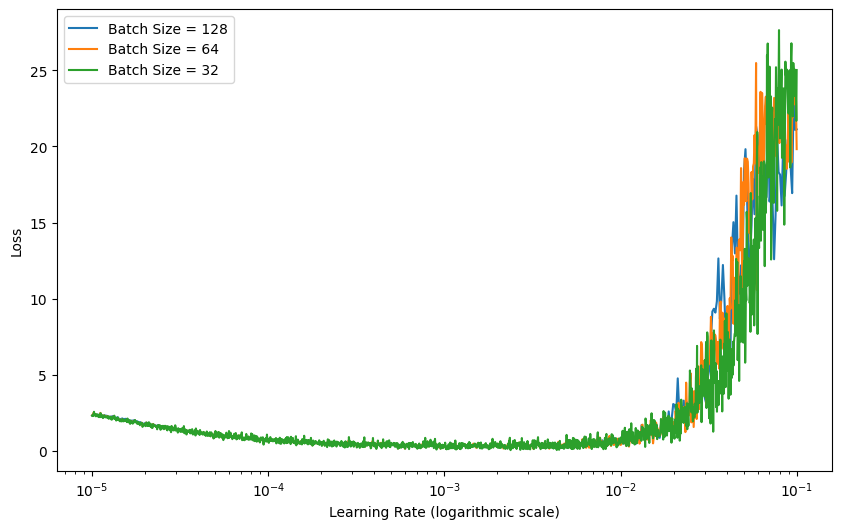

In [ ]:
def run_lr_finder(network, x_train, y_train, batch_size, lr_start=1e-5, lr_end=1e-1, momentum=0.9):
    N = len(x_train)
    np.random.seed(42)
    idx = np.random.permutation(N)
    x_train = x_train[idx]
    y_train = y_train[idx]

    num_batches = (N + batch_size - 1) // batch_size
    learning_rates = np.logspace(np.log10(lr_start), np.log10(lr_end), num_batches)
    losses = []

    for batch_idx, lr in enumerate(learning_rates):
        start = batch_idx * batch_size
        end = min(start + batch_size, N)

        x_batch = x_train[start:end]
        y_batch = y_train[start:end]

        activations, loss = network.forward(x_batch, y_batch)
        losses.append(loss)
        grads_w, grads_b = network.backward(x_batch, y_batch, activations)

        for j in range(len(network.weights)):
            network.memo_w[j] = momentum * network.memo_w[j] + grads_w[j]
            network.memo_b[j] = momentum * network.memo_b[j] + grads_b[j]
            network.weights[j] -= lr * network.memo_w[j]
            network.biases[j] -= lr * network.memo_b[j]

    return learning_rates[:len(losses)], losses


np.random.seed(42)
model_128 = MultiLayerPerceptron()
lr_128, losses_128 = run_lr_finder(model_128, X_train, y_train, batch_size=128)

np.random.seed(42)
model_64 = MultiLayerPerceptron()
lr_64, losses_64 = run_lr_finder(model_64, X_train, y_train, batch_size=64)

np.random.seed(42)
model_32 = MultiLayerPerceptron()
lr_32, losses_32 = run_lr_finder(model_32, X_train, y_train, batch_size=32)

plt.figure(figsize=(10, 6))
plt.plot(lr_128, losses_128, label='Batch Size = 128')
plt.plot(lr_64, losses_64, label='Batch Size = 64')
plt.plot(lr_32, losses_32, label='Batch Size = 32')
plt.xscale('log')
plt.xlabel('Learning Rate (logarithmic scale)')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
def train_network(
    network: MultiLayerPerceptron,
    x_train: NDArray[np.float64],
    y_train: NDArray[np.uint8],
    x_test: NDArray[np.float64],
    y_test: NDArray[np.uint8],
    n_epochs: int = 1,
    batch_size: int = 64,
    lr: float = 1e-3,
    momentum: float = 0.85,
    l2_decay: float = 1e-5,
    plot = False,
):
    N = len(x_train)
    history_loss = []

    for epoch in range(1, n_epochs + 1):
        idx = np.random.permutation(N)
        x_train = x_train[idx]
        y_train = y_train[idx]

        running_loss = 0.0

        for i in range(0, N, batch_size):
            end = min(i + batch_size, N)
            x_batch = x_train[i:end]
            y_batch = y_train[i:end]

            activations, loss = network.forward(x_batch, y_batch)
            grads_w, grads_b = network.backward(x_batch, y_batch, activations)

            for j in range(len(network.sizes) - 2, -1, -1):
                network.memo_w[j] = (
                    momentum * network.memo_w[j] +
                    grads_w[j] +
                    2 * l2_decay * network.weights[j]
                )
                network.memo_b[j] = momentum * network.memo_b[j] + grads_b[j]
                network.weights[j] -= lr * network.memo_w[j]
                network.biases[j] -= lr * network.memo_b[j]

            running_loss += loss * len(x_batch)

        epoch_loss = running_loss / N
        history_loss.append(epoch_loss)

        accuracy = network.evaluate(x_test, y_test, batch_size)
        print(f"Epoch: {epoch}/{n_epochs} | Loss: {epoch_loss:.4f} | Accuracy: {100*accuracy:.2f}%")

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(range(1, n_epochs + 1), history_loss, label="Training Loss")
        plt.title("Training Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

    print("\n")
    return accuracy

In [ ]:
N = len(X_train)
np.random.seed(42)

idx = np.random.permutation(N)
split = int(0.8 * N)

X_train_tune = X_train[idx[:split]]
y_train_tune = y_train[idx[:split]]

X_test_tune = X_train[idx[split:]]
y_test_tune = y_train[idx[split:]]

In [ ]:
for batch_size in [32, 64, 128]:
    print(f"Batch size: {batch_size}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              batch_size=batch_size,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"

        )
    )
    print("\n")

Batch size: 32
Epoch: 1/15 | Loss: 0.3206 | Accuracy: 93.35%
Epoch: 2/15 | Loss: 0.1845 | Accuracy: 94.93%
Epoch: 3/15 | Loss: 0.1482 | Accuracy: 95.51%
Epoch: 4/15 | Loss: 0.1283 | Accuracy: 94.97%
Epoch: 5/15 | Loss: 0.1151 | Accuracy: 95.60%
Epoch: 6/15 | Loss: 0.1045 | Accuracy: 95.86%
Epoch: 7/15 | Loss: 0.0963 | Accuracy: 96.03%
Epoch: 8/15 | Loss: 0.0888 | Accuracy: 95.78%
Epoch: 9/15 | Loss: 0.0846 | Accuracy: 95.60%
Epoch: 10/15 | Loss: 0.0797 | Accuracy: 95.79%
Epoch: 11/15 | Loss: 0.0738 | Accuracy: 95.96%
Epoch: 12/15 | Loss: 0.0719 | Accuracy: 95.82%
Epoch: 13/15 | Loss: 0.0675 | Accuracy: 95.83%
Epoch: 14/15 | Loss: 0.0628 | Accuracy: 96.12%
Epoch: 15/15 | Loss: 0.0597 | Accuracy: 96.09%


Epoch: 1/15 | Loss: 0.3140 | Accuracy: 93.83%
Epoch: 2/15 | Loss: 0.1768 | Accuracy: 95.04%
Epoch: 3/15 | Loss: 0.1416 | Accuracy: 95.21%
Epoch: 4/15 | Loss: 0.1226 | Accuracy: 95.58%
Epoch: 5/15 | Loss: 0.1092 | Accuracy: 95.79%
Epoch: 6/15 | Loss: 0.0989 | Accuracy: 95.85%
Epoch: 7/15

In [ ]:
for momentum in [0.9, 0.8]:
    print(f"momentum: {momentum}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              momentum=momentum,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"
        )
    )
    print("\n")

momentum: 0.9
Epoch: 1/15 | Loss: 0.3133 | Accuracy: 93.57%
Epoch: 2/15 | Loss: 0.1818 | Accuracy: 94.97%
Epoch: 3/15 | Loss: 0.1486 | Accuracy: 94.99%
Epoch: 4/15 | Loss: 0.1285 | Accuracy: 95.20%
Epoch: 5/15 | Loss: 0.1173 | Accuracy: 94.83%
Epoch: 6/15 | Loss: 0.1074 | Accuracy: 95.67%
Epoch: 7/15 | Loss: 0.0987 | Accuracy: 95.77%
Epoch: 8/15 | Loss: 0.0925 | Accuracy: 95.73%
Epoch: 9/15 | Loss: 0.0879 | Accuracy: 95.33%
Epoch: 10/15 | Loss: 0.0837 | Accuracy: 95.62%
Epoch: 11/15 | Loss: 0.0778 | Accuracy: 95.35%
Epoch: 12/15 | Loss: 0.0737 | Accuracy: 95.75%
Epoch: 13/15 | Loss: 0.0693 | Accuracy: 95.51%
Epoch: 14/15 | Loss: 0.0667 | Accuracy: 95.67%
Epoch: 15/15 | Loss: 0.0645 | Accuracy: 95.58%


Epoch: 1/15 | Loss: 0.3030 | Accuracy: 94.09%
Epoch: 2/15 | Loss: 0.1712 | Accuracy: 94.62%
Epoch: 3/15 | Loss: 0.1436 | Accuracy: 94.75%
Epoch: 4/15 | Loss: 0.1273 | Accuracy: 95.31%
Epoch: 5/15 | Loss: 0.1109 | Accuracy: 95.47%
Epoch: 6/15 | Loss: 0.1037 | Accuracy: 95.43%
Epoch: 7/15 

In [ ]:
for l2_decay in [1e-3, 1e-4]:
    print(f"l2 decay: {l2_decay}")
    accuracies = []

    for seed in [42, 43, 44, 45, 46]:
        np.random.seed(seed)
        network = MultiLayerPerceptron()
        accuracies.append(
            train_network(
              network,
              X_train_tune,
              y_train_tune,
              X_test_tune,
              y_test_tune,
              n_epochs=15,
              momentum=0.8,
              l2_decay=l2_decay,
            )
        )

    mean = sum(accuracies) / len(accuracies)
    std = (
        sum((acc - mean) * (acc - mean) for acc in accuracies) /
        (len(accuracies) - 1)
    ) ** 0.5
    print(
        (
            f"Average accuracy: {100*mean:.2f}% | "
            f"Standard deviation: {100*std:.2f}%"
        )
    )
    print("\n")

l2 decay: 0.001
Epoch: 1/15 | Loss: 0.3425 | Accuracy: 93.27%
Epoch: 2/15 | Loss: 0.1972 | Accuracy: 94.62%
Epoch: 3/15 | Loss: 0.1588 | Accuracy: 95.18%
Epoch: 4/15 | Loss: 0.1367 | Accuracy: 94.88%
Epoch: 5/15 | Loss: 0.1232 | Accuracy: 95.27%
Epoch: 6/15 | Loss: 0.1116 | Accuracy: 95.74%
Epoch: 7/15 | Loss: 0.1028 | Accuracy: 95.97%
Epoch: 8/15 | Loss: 0.0967 | Accuracy: 95.72%
Epoch: 9/15 | Loss: 0.0906 | Accuracy: 95.87%
Epoch: 10/15 | Loss: 0.0853 | Accuracy: 95.83%
Epoch: 11/15 | Loss: 0.0795 | Accuracy: 95.75%
Epoch: 12/15 | Loss: 0.0768 | Accuracy: 95.97%
Epoch: 13/15 | Loss: 0.0728 | Accuracy: 95.83%
Epoch: 14/15 | Loss: 0.0689 | Accuracy: 96.09%
Epoch: 15/15 | Loss: 0.0662 | Accuracy: 96.17%


Epoch: 1/15 | Loss: 0.3366 | Accuracy: 93.36%
Epoch: 2/15 | Loss: 0.1894 | Accuracy: 94.83%
Epoch: 3/15 | Loss: 0.1531 | Accuracy: 95.07%
Epoch: 4/15 | Loss: 0.1320 | Accuracy: 95.54%
Epoch: 5/15 | Loss: 0.1178 | Accuracy: 95.73%
Epoch: 6/15 | Loss: 0.1063 | Accuracy: 95.53%
Epoch: 7/1

In [ ]:
np.random.seed(42)
network = MultiLayerPerceptron()
train_network(
    network,
    X_train,
    y_train,
    X_test,
    y_test,
    50,
    momentum=0.8,
    l2_decay=1e-4,
    plot=True,
)


Epoch: 1/50 | Loss: 0.3198 | Accuracy: 93.55%
Epoch: 2/50 | Loss: 0.1841 | Accuracy: 94.83%
Epoch: 3/50 | Loss: 0.1485 | Accuracy: 95.62%
Epoch: 4/50 | Loss: 0.1269 | Accuracy: 95.81%
Epoch: 5/50 | Loss: 0.1144 | Accuracy: 96.06%
Epoch: 6/50 | Loss: 0.1035 | Accuracy: 96.35%
Epoch: 7/50 | Loss: 0.0967 | Accuracy: 96.37%
Epoch: 8/50 | Loss: 0.0886 | Accuracy: 95.96%
Epoch: 9/50 | Loss: 0.0849 | Accuracy: 96.54%
Epoch: 10/50 | Loss: 0.0793 | Accuracy: 96.65%
Epoch: 11/50 | Loss: 0.0752 | Accuracy: 96.44%
Epoch: 12/50 | Loss: 0.0719 | Accuracy: 96.30%
Epoch: 13/50 | Loss: 0.0684 | Accuracy: 96.38%
Epoch: 14/50 | Loss: 0.0656 | Accuracy: 96.60%
Epoch: 15/50 | Loss: 0.0629 | Accuracy: 96.26%
Epoch: 16/50 | Loss: 0.0600 | Accuracy: 96.43%
Epoch: 17/50 | Loss: 0.0580 | Accuracy: 96.31%
Epoch: 18/50 | Loss: 0.0556 | Accuracy: 96.27%
Epoch: 19/50 | Loss: 0.0528 | Accuracy: 96.21%
Epoch: 20/50 | Loss: 0.0507 | Accuracy: 96.31%
Epoch: 21/50 | Loss: 0.0491 | Accuracy: 96.22%
Epoch: 22/50 | Loss: 0